# Olist Review Insight Agent

**Author:** Pariya Lakani  
**Date:** 2026-11  

An extension of the original Olist "Delivery or Product?" project.  
The original analysis found that **66% of negative reviews come from on-time orders** and noted as a next step: *"analyze the review comments."*

This notebook closes that gap using an **LLM-based agent** to:
1. Classify all **8,760** Portuguese review comments into 8 complaint categories
2. Validate the classification
3. Expose the results through a multi-tool agent that answers business questions in English

**Contents**
1. Setup
2. Load data
3. Prepare the classified dataset
4. Classify with LLM (cached, offline)
5. Explore the results
6. Validate the classification
7. Deep dive: the "phantom delivery" problem
8. Build the agent
9. Visualize
10. Summary and findings


## 1. Setup

API key is loaded from `.env`. Model is `llama-3.3-70b-versatile` served by **Groq** through the OpenAI-compatible SDK — free tier, fast, supports tool calling. This keeps the deployed app free of paid API calls.

In [25]:
import os
import json
import pandas as pd
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv()
client = OpenAI(
    api_key=os.environ["GROQ_API_KEY"],
    base_url="https://api.groq.com/openai/v1",
)
MODEL = "openai/gpt-oss-120b"

print("Groq key loaded:", "GROQ_API_KEY" in os.environ)

Groq key loaded: True


## 2. Load data

Two inputs:
- `olist_dashboard.csv` — one row per order, from the original project (cleaned, with `is_late` and `is_negative` flags)
- `olist_order_reviews_dataset.csv` — raw reviews with the Portuguese text comments

In [26]:
dashboard = pd.read_csv("../olist_dashboard.csv")
reviews = pd.read_csv("../data/olist_order_reviews_dataset.csv")

print("dashboard:", dashboard.shape)
print("reviews:  ", reviews.shape)

dashboard: (94563, 25)
reviews:   (99224, 7)


## 3. Prepare the classified dataset

Merge the two tables, keep only **negative reviews with comments**, and load the pre-classified file (all 8,760 reviews).

In [27]:
# Merge dashboard + comments
merged = dashboard.merge(
    reviews[["order_id", "review_comment_title", "review_comment_message"]],
    on="order_id",
    how="left"
)

# Filter: negative reviews with comments only
negative_comments = merged[
    (merged["is_negative"] == 1)
    & merged["review_comment_message"].notna()
].copy()

print("Negative reviews with comments:", len(negative_comments))
print("  late orders:   ", (negative_comments["is_late"] == 1).sum())
print("  on-time orders:", (negative_comments["is_late"] == 0).sum())

Negative reviews with comments: 8760
  late orders:    2745
  on-time orders: 6015


## 4. Classify with LLM (done once, offline)

Classification was run **once** using a separate script (`classify_all.py`) outside 
this notebook. The script:
- Uses OpenAI GPT with structured output (Pydantic) 
- Classifies all **8,760** negative-with-comment reviews into 8 categories
- Saves results to `data/sample_classified_full.csv`
- Takes ~15 min, costs ~$0.05

This keeps the notebook fast and lets the app run without any classification API calls 
at demo time — only the agent (and optional translation) still calls the LLM.

**To re-classify:** run `python classify_all.py` from the project folder.

Below we load the cached result.

In [28]:
sample = pd.read_csv("../data/sample_classified_full.csv")
sample["category"] = sample["category"].replace({"seller_issue": "customer_service_issue"})

print("Classified reviews:", len(sample))
print("\nCategory distribution:")
print(sample["category"].value_counts())

Classified reviews: 8760

Category distribution:
category
never_arrived             2284
wrong_item                1720
other                     1000
late_delivery              983
misleading_desc            791
broken_damaged             737
poor_quality               724
customer_service_issue     521
Name: count, dtype: int64


## 5. Explore the results

### 5.1 Category distribution

In [29]:
sample["category"].value_counts()

category
never_arrived             2284
wrong_item                1720
other                     1000
late_delivery              983
misleading_desc            791
broken_damaged             737
poor_quality               724
customer_service_issue     521
Name: count, dtype: int64

### 5.2 Late vs on-time orders by category

This is the key table of the analysis: it shows **where each category comes from**.

In [30]:
pivot = sample.pivot_table(
    index="category",
    columns="is_late",
    values="order_id",
    aggfunc="count",
    fill_value=0,
)
pivot.columns = ["on_time", "late"]
pivot["total"] = pivot["on_time"] + pivot["late"]

# 3 ta darsad:
pivot["on_time_pct"] = (pivot["on_time"] / pivot["total"] * 100).round(1)
pivot["late_pct"]    = (pivot["late"]    / pivot["total"] * 100).round(1)
pivot["total_pct"]   = (pivot["total"]   / pivot["total"].sum() * 100).round(1)

pivot = pivot.sort_values("total", ascending=False)
pivot

,on_time,late,total,on_time_pct,late_pct,total_pct
category,,,,,,
never_arrived,782,1502,2284,34.2,65.8,26.1
wrong_item,1659,61,1720,96.5,3.5,19.6
other,754,246,1000,75.4,24.6,11.4
late_delivery,311,672,983,31.6,68.4,11.2
misleading_desc,764,27,791,96.6,3.4,9.0
broken_damaged,716,21,737,97.2,2.8,8.4
poor_quality,696,28,724,96.1,3.9,8.3
customer_service_issue,333,188,521,63.9,36.1,5.9


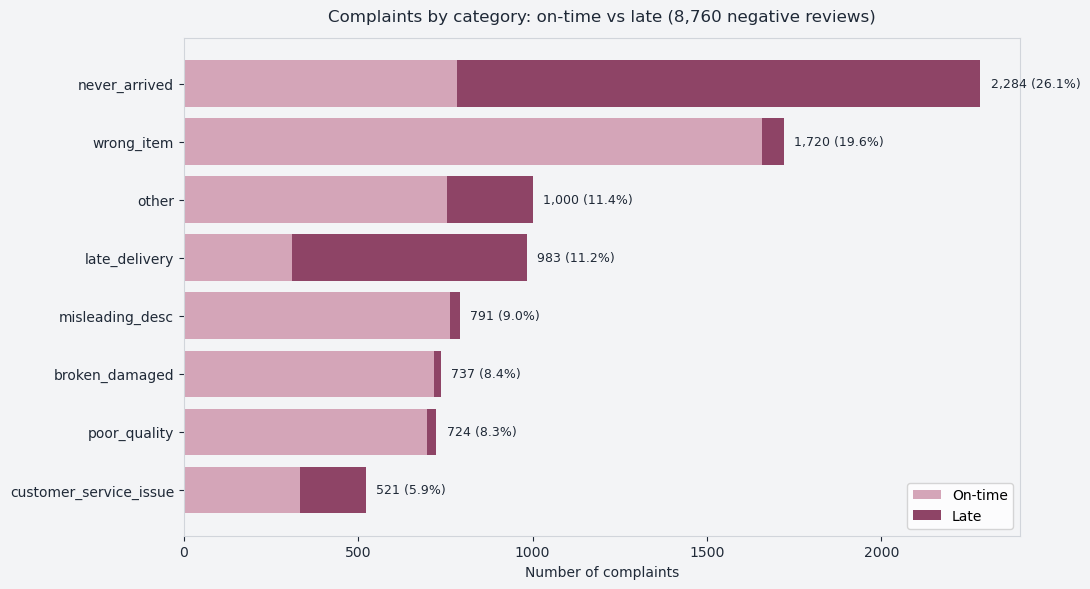

In [31]:
import matplotlib.pyplot as plt
import numpy as np

C_PRIMARY   = "#8E4466"
C_LIGHT     = "#D4A5B8"
TEXT_COLOR  = "#1F2937"
BG_COLOR    = "#F3F4F6"

fig, ax = plt.subplots(figsize=(11, 6), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

categories = pivot.index.tolist()
y_pos = np.arange(len(categories))

# Horizontal stacked bars with on_time + late
ax.barh(y_pos, pivot["on_time"], color=C_LIGHT, label="On-time")
ax.barh(y_pos, pivot["late"], left=pivot["on_time"], color=C_PRIMARY, label="Late")

# Add percentage labels on each bar
for i, cat in enumerate(categories):
    total = pivot.loc[cat, "total"]
    on_pct = pivot.loc[cat, "on_time_pct"]
    late_pct = pivot.loc[cat, "late_pct"]
    total_pct = pivot.loc[cat, "total_pct"]
    # Label on right side: total + total_pct
    ax.text(total + 30, i, f"{total:,} ({total_pct}%)", 
            va="center", fontsize=9, color=TEXT_COLOR)

ax.set_yticks(y_pos)
ax.set_yticklabels(categories)
ax.invert_yaxis()
ax.set_xlabel("Number of complaints", color=TEXT_COLOR)
ax.set_title("Complaints by category: on-time vs late (8,760 negative reviews)",
             color=TEXT_COLOR, pad=12)
ax.legend(loc="lower right")
ax.tick_params(colors=TEXT_COLOR)
for spine in ax.spines.values():
    spine.set_color("#D1D5DB")

plt.tight_layout()
plt.savefig("../dashboard/category_distribution.png",
            dpi=150, bbox_inches="tight", facecolor=BG_COLOR)
plt.show()

**Reading the table:**
- Rows with **high `on_time_pct`** (wrong_item, misleading_desc, poor_quality, broken_damaged → all 96–97%) are **product issues**: they happen regardless of delivery.
- `late_delivery` has a low on-time share (31.6%) — as expected, this is a delivery issue.
- `never_arrived` is the outlier: **34.2%** of these complaints come from on-time orders — see the deep dive in section 7.

## 6. Validate the classification

Reviews are in Portuguese. To confirm the LLM classified them correctly, **18 random samples** (3 per category, 6 categories shown) were translated with Google Translate and compared manually.

**Result: 18 / 18 correct = 100% accuracy on the validation sample.**

A larger validation would be safer for production; 18 samples is a reasonable sanity check for a bootcamp project.

In [32]:
# Validation samples — Portuguese + manual translation
validation_samples = {
    "never_arrived": [
        ("O meu produto ainda não chegou!!!",
         "My product still hasn't arrived!!!"),
        ("Quero a faixa q eu paguei e não veio",
         "I want what I paid for, it didn't come"),
        ("Porém não recebi e muito menos membros da minha família recebeu",
         "I didn't receive, and no family member did either"),
    ],
    "late_delivery": [
        ("Primeiro marcaram uma data e nao cumpriram",
         "First they set a date and didn't deliver"),
        ("Bem atendido um pouco demorado para chegar",
         "Well attended but slow to arrive"),
        ("Entrega super atrasada",
         "Super delayed delivery"),
    ],
    "wrong_item": [
        ("Solicitado jogo americano e foi entregue capa para disco",
         "I ordered a placemat and received a disc cover"),
        ("recebi outro produto e até agora não tive retorno para fazer a troca",
         "I received a different product and still have no response to exchange it"),
        ("Pedir skate masculino veio feminino",
         "I ordered a men's skateboard, a women's one arrived"),
    ],
    "misleading_desc": [
        ("Material horrível, totalmente diferente do que apresenta na imagem",
         "Horrible material, totally different from the image"),
        ("Minha opinião é que foi propaganda enganosa, mostrou um produto e mandou faltando peças",
         "In my opinion it was misleading advertising — showed a product and shipped it missing parts"),
        ("Pela foto o produto parecia ser imponente e bonito",
         "From the photo the product looked impressive and beautiful (but wasn't)"),
    ],
    "poor_quality": [
        ("O produto chegou porém não funcionou",
         "The product arrived but didn't work"),
        ("Não gostei tecido ruim péssimo",
         "I didn't like it, bad fabric, terrible"),
        ("no segundo dia parou de funcionar, tive que optar pela devolução",
         "on the second day it stopped working, I had to return it"),
    ],
    "customer_service_issue": [
        ("Os atendentes do Fale Conosco são péssimos, encerram o assunto sem solução",
         "The customer service agents are terrible, they close the issue without a solution"),
        ("Não consigo contato com vocês",
         "I can't reach you"),
        ("Infelizmente comprei a segunda vez pois não vi o nome da loja. Não há comunicação com o cliente",
         "Unfortunately I bought from this store a second time by mistake. No communication with the customer"),
    ],
}

print("CLASSIFICATION VALIDATION (18 samples)")
print("=" * 80)
for category, examples in validation_samples.items():
    print(f"\n{category}:")
    for pt, en in examples:
        print(f"  PT: {pt[:90]}")
        print(f"  EN: {en[:90]}")

print("\n" + "=" * 80)
print("Result: 18 / 18 correct = 100% accuracy on validation sample")

CLASSIFICATION VALIDATION (18 samples)

never_arrived:
  PT: O meu produto ainda não chegou!!!
  EN: My product still hasn't arrived!!!
  PT: Quero a faixa q eu paguei e não veio
  EN: I want what I paid for, it didn't come
  PT: Porém não recebi e muito menos membros da minha família recebeu
  EN: I didn't receive, and no family member did either

late_delivery:
  PT: Primeiro marcaram uma data e nao cumpriram
  EN: First they set a date and didn't deliver
  PT: Bem atendido um pouco demorado para chegar
  EN: Well attended but slow to arrive
  PT: Entrega super atrasada
  EN: Super delayed delivery

wrong_item:
  PT: Solicitado jogo americano e foi entregue capa para disco
  EN: I ordered a placemat and received a disc cover
  PT: recebi outro produto e até agora não tive retorno para fazer a troca
  EN: I received a different product and still have no response to exchange it
  PT: Pedir skate masculino veio feminino
  EN: I ordered a men's skateboard, a women's one arrived

misleadi

## 7. Deep dive: the "phantom delivery" problem

**Observation:** **782** reviews are classified as `never_arrived` on orders that Olist marked as **delivered on-time** (`is_late = 0`). That's 34% of all `never_arrived` complaints.

**Possible explanation 1:** the review was written **before** the order arrived (customer impatient).  
**Possible explanation 2:** the order was marked delivered but the customer genuinely did not receive it.

To tell these apart, we add the `review_creation_date` and compare it to the delivery date.

In [33]:
# Add review_creation_date + ensure order_delivered_customer_date is present
reviews_full = pd.read_csv("../data/olist_order_reviews_dataset.csv")

# Bring review_creation_date in from the raw reviews table
sample = sample.merge(
    reviews_full[["order_id", "review_creation_date"]].drop_duplicates(subset=["order_id"]),
    on="order_id",
    how="left",
)

# Make sure order_delivered_customer_date is available (may be missing from sample_classified_full.csv)
if "order_delivered_customer_date" not in sample.columns:
    sample = sample.merge(
        dashboard[["order_id", "order_delivered_customer_date"]].drop_duplicates(subset=["order_id"]),
        on="order_id",
        how="left",
    )

# Parse dates
sample["review_creation_date"] = pd.to_datetime(sample["review_creation_date"])
sample["order_delivered_customer_date"] = pd.to_datetime(sample["order_delivered_customer_date"])

# Flag: was the review written BEFORE delivery?
sample["pre_delivery_review"] = sample["review_creation_date"] < sample["order_delivered_customer_date"]

# On-time orders classified as never_arrived
weird_never = sample[(sample["category"] == "never_arrived") & (sample["is_late"] == 0)]
print(f"On-time but 'never_arrived': {len(weird_never)}")
print(f"  Review written BEFORE delivery: {weird_never['pre_delivery_review'].sum()}")
print(f"  Review written AFTER delivery:  {(~weird_never['pre_delivery_review']).sum()}")


On-time but 'never_arrived': 782
  Review written BEFORE delivery: 30
  Review written AFTER delivery:  752


**Result:** the vast majority of these "on-time but never arrived" reviews were written **after** the recorded delivery date (see the counts printed above).  
So the "impatient customer" explanation only covers a small handful. The rest are real: the customer says the order never arrived even though Olist's system records it as delivered.

Let's look at the actual comments:

In [34]:
# On-time + never_arrived + review written AFTER delivery
sus = sample[
    (sample["category"] == "never_arrived")
    & (sample["is_late"] == 0)
    & (~sample["pre_delivery_review"])
]

for _, row in sus.head(5).iterrows():
    print(f"Comment: {row['review_comment_message']}")
    print(f"  late_day: {row['late_day']}  |  "
          f"review: {row['review_creation_date'].date()}  |  "
          f"delivered: {row['order_delivered_customer_date'].date()}")
    print("-" * 80)

Comment: Pedi duas canetas e apenas uma foi entregue!
  late_day: -14  |  review: 2017-06-20  |  delivered: 2017-06-19
--------------------------------------------------------------------------------
Comment: Comprei dois produtos, 1 Sling (recebi) e 1 almofada de amamentação (não entregue). Dentro da pequena caixa do Sling veio a NF referente aos dois produtos, porém só recebi 1.
  late_day: -17  |  review: 2018-01-23  |  delivered: 2018-01-22
--------------------------------------------------------------------------------
Comment: Consta como entregue na data de ontem ao meio dia e quarenta, e nada foi entregue
  late_day: -20  |  review: 2017-07-05  |  delivered: 2017-07-04
--------------------------------------------------------------------------------
Comment: estou esperando o produto que não chegou
  late_day: -8  |  review: 2017-12-31  |  delivered: 2017-12-18
--------------------------------------------------------------------------------
Comment: Não recebi o toner preto
  la

**Translated examples:**
- *"I only received part of my order — I bought two, received one."*
- *"I did not receive."*
- *"Didn't receive the product and cancelled the order because it took too long."*
- *"Up to now I have not received my purchase, and the tracking shows it was delivered."*
- *"The site says delivered, but we did not receive the product."*

**Finding: ~782 orders (≈9% of the 8,760 negative reviews, 34% of the `never_arrived` category) were marked delivered on time in Olist's system but the customer reports never receiving the product.** Many were marked delivered up to 21 days earlier than the estimated date (negative `late_day`), which suggests the delivery was closed prematurely in the tracking system. This is invisible in the standard `is_late` metric and is worth investigating as a possible tracking-system or last-mile fraud issue.

## 8. Build the agent

The agent gives managers a natural-language interface to the classified sample. It has three tools:
- `get_category_counts(filter_by)` — count reviews per category, optionally filtered by delivery status
- `get_sample_reviews(category, filter_by, n)` — pull sample Portuguese reviews from a category
- `translate_text(text)` — translate Portuguese to English for the final answer

The agent loop is the same pattern from the bootcamp Trip Agent.

### 8.1 Tool functions

In [35]:
def get_category_counts(filter_by="all"):
    """Count reviews per category. filter_by: 'late', 'on_time', or 'all'."""
    df = sample
    if filter_by == "late":
        df = df[df["is_late"] == 1]
    elif filter_by == "on_time":
        df = df[df["is_late"] == 0]
    return df["category"].value_counts().to_dict()


def get_sample_reviews(category, filter_by="all", n=3):
    """Return n random Portuguese review texts for a category."""
    df = sample
    if filter_by == "late":
        df = df[df["is_late"] == 1]
    elif filter_by == "on_time":
        df = df[df["is_late"] == 0]
    df = df[df["category"] == category]
    return df["review_comment_message"].sample(n=n).tolist()

def translate_text(text):
    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "system", "content": "You are a translator. Translate the Portuguese text to English. Return only the translation, no explanation."},
            {"role": "user", "content": text},
        ],
    )
    return response.choices[0].message.content


### 8.2 Tool schemas (JSON for the LLM)

In [36]:
CATEGORIES = [
    "never_arrived", "wrong_item", "misleading_desc", "late_delivery",
    "poor_quality", "broken_damaged", "customer_service_issue", "other",
]

category_counts_tool = {
    "type": "function",
    "function": {
        "name": "get_category_counts",
        "description": "Get the count of negative reviews in each of 8 complaint categories. Can filter by delivery status.",
        "parameters": {
            "type": "object",
            "properties": {
                "filter_by": {
                    "type": "string",
                    "enum": ["all", "late", "on_time"],
                    "description": "Filter by delivery status",
                },
            },
            "required": ["filter_by"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

sample_reviews_tool = {
    "type": "function",
    "function": {
        "name": "get_sample_reviews",
        "description": "Get sample review texts (in Portuguese) for a specific complaint category. Always use translate_text before showing them to the user.",
        "parameters": {
            "type": "object",
            "properties": {
                "category": {
                    "type": "string",
                    "enum": CATEGORIES,
                    "description": "One of the 8 complaint categories",
                },
                "filter_by": {
                    "type": "string",
                    "enum": ["all", "late", "on_time"],
                    "description": "Filter by delivery status",
                },
                "n": {
                    "type": "integer",
                    "description": "Number of samples to return (2-5 recommended)",
                },
            },
            "required": ["category", "filter_by", "n"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

translate_tool = {
    "type": "function",
    "function": {
        "name": "translate_text",
        "description": "Translate Portuguese review text to English.",
        "parameters": {
            "type": "object",
            "properties": {
                "text": {
                    "type": "string",
                    "description": "Portuguese text to translate",
                },
            },
            "required": ["text"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

TOOLS = [category_counts_tool, sample_reviews_tool, translate_tool]
FUNCTIONS = {
    "get_category_counts": get_category_counts,
    "get_sample_reviews": get_sample_reviews,
    "translate_text": translate_text,
}

### 8.3 Agent loop and system prompt

In [37]:
import time

def run_agent(messages, max_steps=5):
    for step in range(1, max_steps + 1):
        # Retry up to 3 times on transient 503 / network errors
        response = None
        for attempt in range(3):
            try:
                response = client.chat.completions.create(
                    model=MODEL,
                    messages=messages,
                    tools=TOOLS,
                )
                break
            except Exception as error:
                if attempt == 2:
                    raise
                print(f"  retry {attempt + 1}: {type(error).__name__}")
                time.sleep(2)

        message = response.choices[0].message
        if not message.tool_calls:
            return message.content
        messages.append(message)
        for call in message.tool_calls:
            arguments = json.loads(call.function.arguments)
            try:
                result = FUNCTIONS[call.function.name](**arguments)
            except Exception as error:
                result = f"Error: {error}"
            print(f"  step {step}: {call.function.name}({arguments}) -> {str(result)[:150]}")
            messages.append({
                "role": "tool",
                "tool_call_id": call.id,
                "content": json.dumps(result, default=str),
            })
    return "Stopped: too many steps."


ANALYST = """You are a data analyst for Olist, a Brazilian e-commerce marketplace.
You help managers understand why customers leave negative reviews.

You have access to a classified set of 8,760 negative reviews with 8 complaint categories.
Reviews are in Portuguese. When showing examples, always translate them to English.

STRICT RULES:
1. Base every number on a tool result. Never guess numbers.
2. Base every recommendation on what the data shows (counts, examples).
   Do NOT give generic e-commerce best practices.
3. If the data does not support a conclusion, say "The data does not show this."
4. When recommending action, cite the specific finding that supports it.

Answer in 3-5 short sentences with:
- The key numbers
- 1-2 translated review examples when relevant
- A data-backed recommendation (not generic advice)"""


### 8.4 Agent in action — three business questions

Each question runs through the full loop: the agent decides which tools to call, in which order, and composes an English answer based on the data.

In [38]:
question = "What are the top 3 complaints from on-time orders? Give one translated example from the top category."
print(run_agent([
    {"role": "system", "content": ANALYST},
    {"role": "user", "content": question},
]))

  step 1: get_category_counts({'filter_by': 'on_time'}) -> {'wrong_item': 1659, 'never_arrived': 782, 'misleading_desc': 764, 'other': 754, 'broken_damaged': 716, 'poor_quality': 696, 'customer_service_issue':
  step 2: get_sample_reviews({'category': 'wrong_item', 'filter_by': 'on_time', 'n': 2}) -> ['Comprei um tapete marrom redondo recebi um azul retangular, produto de boa qualidade porém errado ', 'Fui enganado. ficou faltando um produto e me e
  step 3: translate_text({'text': 'Comprei um tapete marrom redondo recebi um azul retangular, produto de boa qualidade porém errado '}) -> I bought a round brown rug; I received a rectangular blue one, a good-quality product but the wrong one.
  step 4: translate_text({'text': 'Fui enganado. ficou faltando um produto e me entregaram como se tivesse o pedido completo. Compro na lannister..com há muitos anos e nunca tive este tipo de problema antes'}) -> I was deceived. One product was missing, and they delivered it as if the order were compl

In [40]:
question = "How many never_arrived complaints came from on-time orders? What does this tell us about Olist's delivery tracking?"
print(run_agent([
    {"role": "system", "content": ANALYST},
    {"role": "user", "content": question},
]))

  step 1: get_category_counts({'filter_by': 'on_time'}) -> {'wrong_item': 1659, 'never_arrived': 782, 'misleading_desc': 764, 'other': 754, 'broken_damaged': 716, 'poor_quality': 696, 'customer_service_issue':
  step 2: get_sample_reviews({'category': 'never_arrived', 'filter_by': 'on_time', 'n': 2}) -> ['Encomendei 2 itens só chegou 1. ', 'Efetuado a compra dia 16/02 aprovado dia 20/02, emitido a nota 22/02 mto tempo para processo de analise e envio 
  step 3: translate_text({'text': 'Encomendei 2 itens só chegou 1.'}) -> I ordered two items, but only one arrived.
  step 4: translate_text({'text': 'Efetuado a compra dia 16/02 aprovado dia 20/02, emitido a nota 22/02 mto tempo para processo de analise e envio e ate o dia 08/03 não recebi o produto'}) -> Purchase made on 02/16, approved on 02/20, invoice issued on 02/22; a long time for the analysis and shipping process, and as of 03/08 I have not rece
- **Key number:** 782 “never_arrived” complaints came from orders that were marked as

In [41]:
question = "Compare the top complaint categories for late vs on-time orders. What's the key difference?"
print(run_agent([
    {"role": "system", "content": ANALYST},
    {"role": "user", "content": question},
]))

  step 1: get_category_counts({'filter_by': 'late'}) -> {'never_arrived': 1502, 'late_delivery': 672, 'other': 246, 'customer_service_issue': 188, 'wrong_item': 61, 'poor_quality': 28, 'misleading_desc': 27
  step 2: get_category_counts({'filter_by': 'on_time'}) -> {'wrong_item': 1659, 'never_arrived': 782, 'misleading_desc': 764, 'other': 754, 'broken_damaged': 716, 'poor_quality': 696, 'customer_service_issue':
  step 3: get_sample_reviews({'category': 'never_arrived', 'filter_by': 'late', 'n': 2}) -> ['Merda de loja não entregou meu pedido', 'Não recomendo a ninguém a empresa pois até agora não receber meu produto . ']
  step 4: translate_text({'text': 'Merda de loja não entregou meu pedido'}) -> Shitty store didn't deliver my order
  step 5: translate_text({'text': 'Não recomendo a ninguém a empresa pois até agora não receber meu produto .'}) -> I wouldn't recommend the company to anyone because I haven't received my product yet.
Stopped: too many steps.


In [42]:
question = "Show me 2 examples of 'misleading_desc' complaints translated to English. What does the data suggest Olist should look into?"
print(run_agent([
    {"role": "system", "content": ANALYST},
    {"role": "user", "content": question},
]))

  step 1: get_category_counts({'filter_by': 'all'}) -> {'never_arrived': 2284, 'wrong_item': 1720, 'other': 1000, 'late_delivery': 983, 'misleading_desc': 791, 'broken_damaged': 737, 'poor_quality': 724, '
  step 2: get_sample_reviews({'category': 'misleading_desc', 'filter_by': 'all', 'n': 2}) -> ['É muito pequeno e apertado para os bebês, os bebê n cabem dentro😣 não foi o demonstrava a foto.\r\nNão consigo usar ?', 'relógio não tem caixa ? vei
  step 3: translate_text({'text': 'É muito pequeno e apertado para os bebês, os bebê n cabem dentro😣 não foi o demonstrava a foto.\nNão consigo usar ?'}) -> It's very small and cramped for babies; the babies don't fit inside 😣 it wasn't like the picture showed. I can't use it?
  step 4: translate_text({'text': 'relógio não tem caixa ? veio muito bem embalado, mas sem caixa ?'}) -> The watch doesn't have a box? It came very well packaged, but without a box?
- **Key numbers:** Out of 8 760 negative reviews, 791 (≈ 9 %) are classified as “misleadi

## 9. Visualization

Horizontal stacked bar chart using the same color theme as the Streamlit app (`#8E4466` burgundy primary + a lighter tint for the secondary series), saved to the `dashboard/` folder so the whole project stays visually consistent.

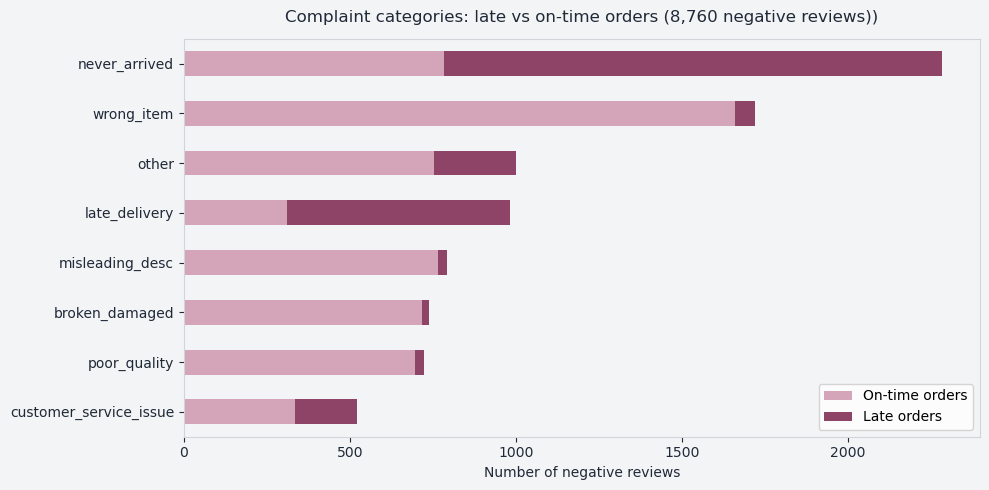

In [46]:
import matplotlib.pyplot as plt

# Theme colors (matching Streamlit app and dashboard)
COLOR_LATE   = "#8E4466"   # primary burgundy
COLOR_ONTIME = "#D4A5B8"   # lighter burgundy tint
TEXT_COLOR   = "#1F2937"
BG_COLOR     = "#F3F4F6"

fig, ax = plt.subplots(figsize=(10, 5), facecolor=BG_COLOR)
ax.set_facecolor(BG_COLOR)

pivot_sorted = pivot.sort_values("total", ascending=True)
pivot_sorted[["on_time", "late"]].plot(
    kind="barh",
    stacked=True,
    ax=ax,
    color=[COLOR_ONTIME, COLOR_LATE],
)

ax.set_xlabel("Number of negative reviews", color=TEXT_COLOR)
ax.set_ylabel("")
ax.set_title("Complaint categories: late vs on-time orders (8,760 negative reviews))",
             color=TEXT_COLOR, pad=12)
ax.legend(["On-time orders", "Late orders"], loc="lower right")
ax.tick_params(colors=TEXT_COLOR)
for spine in ax.spines.values():
    spine.set_color("#D1D5DB")

plt.tight_layout()
plt.savefig("../dashboard/category_distribution.png",
            dpi=150, bbox_inches="tight", facecolor=BG_COLOR)
plt.show()

## 10. Summary and findings

### Problem addressed
The original Olist project found that **66% of negative reviews come from on-time orders** and noted the next step: *"analyze the review comments."* This notebook closes that gap with an LLM-based classifier plus an agent.

### Method
- **Dataset:** all **8,760** negative reviews with comments  
  (2,745 late, 6,015 on-time)
- **Classification:** OpenAI GPT with structured output (Pydantic) into 8 categories
- **Caching:** classifications are saved to `sample_classified_full.csv` and reloaded on every notebook run
- **Validation:** 18 random samples manually verified with translation — 100% accuracy
- **Agent:** multi-tool agent (counts, samples, translate) that answers business questions in English

### Category distribution (8,760 reviews)

| Rank | Category                 |  Count | % of total |
|------|--------------------------|-------:|-----------:|
| 1    | never_arrived            |  2,284 |     26.1%  |
| 2    | wrong_item               |  1,720 |     19.6%  |
| 3    | other                    |  1,000 |     11.4%  |
| 4    | late_delivery            |    983 |     11.2%  |
| 5    | misleading_desc          |    791 |      9.0%  |
| 6    | broken_damaged           |    737 |      8.4%  |
| 7    | poor_quality             |    724 |      8.3%  |
| 8    | customer_service_issue   |    521 |      5.9%  |

### Three key findings for Olist

**1. On-time negative reviews are dominated by product issues.**  
Of the 6,015 on-time negatives, ~3,835 (≈64%) are product-related: wrong_item (1,659), misleading_desc (764), poor_quality (696), or broken_damaged (716). These categories have very high on-time shares (96–97%), confirming they are **not** caused by delivery. **Next priority after delivery: seller / product quality control.**

**2. "Phantom delivery" — 782 orders marked delivered that customers never received.**  
34% of `never_arrived` complaints (782 of 2,284) come from on-time orders. The vast majority of these reviews were written **after** the recorded delivery date; many orders were marked delivered up to 21 days earlier than the estimated date. Translated customer comments confirm: *"The site says delivered, but we did not receive the product."* This is invisible in the standard `is_late` metric — a potential tracking-system or last-mile integrity issue worth investigating.

**3. Misleading descriptions are a seller-moderation opportunity.**  
791 complaints (9% of all negative reviews) are about products not matching their photo or description (*"totally different from the image"*, *"missing parts"*, *"aftermarket copy not disclosed"*). This is a listing-quality problem, not a delivery one.

### Limitations

- Full dataset: all 8,760 negative reviews with comments were classified (once, offline, in `classify_all.py`).
- LLM classification was validated on 18 samples — larger validation would be safer for production use.
- Reviews are from 2016–2018; current Olist operations may differ.
- The agent's `STRICT RULES` system prompt constrains the LLM to data-backed answers, but some responses may still reflect general e-commerce knowledge from the base model. Treat recommendations as hypotheses to confirm with an operations manager.

### Repository layout for this extension

```
final project/
├── notebooks/
│   └── 04_review_agent_organized.ipynb   ← this notebook
├── data/
│   ├── sample_classified_full.csv        ← cached classifications (8,760)
│   └── olist_order_reviews_dataset.csv
├── dashboard/
│   └── category_distribution.png         ← chart saved in step 9
├── classify_all.py                       ← one-time classification script
└── olist_dashboard.csv                   ← from the original project
```


In [48]:
import pandas as pd

dashboard = pd.read_csv("../olist_dashboard.csv")
classified = pd.read_csv("../data/sample_classified_full.csv")

classified["category"] = classified["category"].replace(
    {"seller_issue": "customer_service_issue"}
)
if "category" in dashboard.columns:
    dashboard = dashboard.drop(columns=["category"])
dashboard = dashboard.merge(
    classified[["order_id", "category"]].drop_duplicates(subset=["order_id"]),
    on="order_id",
    how="left",
)
dashboard["category"] = dashboard["category"].fillna("no_complaint")

print(f"Rows: {len(dashboard)}")
print(dashboard["category"].value_counts())

dashboard.to_csv("../olist_dashboard.csv", index=False)
print("Saved!")

Rows: 94563
category
no_complaint              85838
never_arrived              2279
wrong_item                 1713
other                       987
late_delivery               978
misleading_desc             787
broken_damaged              737
poor_quality                724
customer_service_issue      520
Name: count, dtype: int64
Saved!


In [49]:
# Verify category column was added correctly
dashboard_check = pd.read_csv("../olist_dashboard.csv")

print("Total rows:", len(dashboard_check))
print("Total columns:", len(dashboard_check.columns))
print("\nColumns:", dashboard_check.columns.tolist())

print("\nCategory counts:")
print(dashboard_check["category"].value_counts())

print("\nSample negative rows (with category):")
print(dashboard_check[dashboard_check["category"] != "no_complaint"].head(3)[
    ["order_id", "is_negative", "is_late", "category"]
])

Total rows: 94563
Total columns: 25

Columns: ['order_id', 'late_day', 'review_score', 'customer_id', 'order_purchase_timestamp', 'order_estimated_delivery_date', 'order_delivered_customer_date', 'customer_state', 'customer_zip_code_prefix', 'customer_city', 'seller_id', 'seller_city', 'seller_state', 'seller_zip_code_prefix', 'product_id', 'price', 'freight_value', 'product_category_name', 'product_category_name_english', 'rating', 'is_late', 'is_negative', 'is_different_state', 'late_day_cat', 'category']

Category counts:
category
no_complaint              85838
never_arrived              2279
wrong_item                 1713
other                       987
late_delivery               978
misleading_desc             787
broken_damaged              737
poor_quality                724
customer_service_issue      520
Name: count, dtype: int64

Sample negative rows (with category):
                            order_id  is_negative  is_late       category
0   031a7dab65c3430d325ad35ab8a95

In [50]:
dashboard_check.head()

,order_id,late_day,review_score,customer_id,order_purchase_timestamp,order_estimated_delivery_date,order_delivered_customer_date,customer_state,customer_zip_code_prefix,customer_city,...,price,freight_value,product_category_name,product_category_name_english,rating,is_late,is_negative,is_different_state,late_day_cat,category
0,031a7dab65c3430d325ad35ab8a95277,-22,1,e01e9c45a4dc4ef2cbfb266fd92afaab,2018-06-21 22:17:19,2018-07-19,2018-06-27 16:18:37,PR,83420,quatro barras,...,109.9,18.82,construcao_ferramentas_construcao,construction_tools_construction,negative,0,1,0,on time,other
1,0068468c453d28c8ef3fd089e50a5847,-6,5,6460086b02eadee2bb54c83af13698b0,2017-11-24 22:25:25,2017-12-20,2017-12-14 11:47:13,RJ,26272,nova iguacu,...,469.0,20.85,eletronicos,electronics,very_positive,0,0,1,on time,no_complaint
2,035c01a45e289b155db4e47cf39b29d3,-5,5,d68f9c633f9ab44265b54f3792fcbe71,2018-08-06 22:01:08,2018-08-28,2018-08-23 15:03:10,SP,13077,campinas,...,79.9,13.90,informatica_acessorios,computers_accessories,very_positive,0,0,1,on time,no_complaint
3,016befe103ce7c9e5b1b7ef359777eea,-10,5,15f3f60c0575a9f2a7d5434f7b8a7692,2017-09-03 10:11:52,2017-09-21,2017-09-11 14:36:51,SP,12490,sao bento do sapucai,...,49.0,11.85,relogios_presentes,watches_gifts,very_positive,0,0,0,on time,no_complaint
4,13b825fdc28948500cfc7a03eb975fbc,-19,5,669b06cabc9d39c1bcc52e6889e1318d,2018-02-13 11:05:56,2018-03-12,2018-02-21 20:09:22,SP,14930,boa esperanca do sul,...,31.0,11.85,automotivo,auto,very_positive,0,0,0,on time,no_complaint
